# Knowledge-graph construction: pipeline walkthrough (concise)

*Short version. The narrated version with more examples is [01_kg_construction_detailed.ipynb](01_kg_construction_detailed.ipynb).*

This notebook builds the maintenance knowledge graph from the shared folder (15 files: text,
logs, CSV, PDF) one stage at a time, and shows the output of each stage.

**Design principle:** agents decide what a file is and *point at* source text; code verifies
every pointer before anything is published. Items that fail verification are held for review
and kept out of answers; the rest of the file still publishes.

| # | Stage | Done by | Output |
|---|---|---|---|
| 1 | Read | code | text, hash, line and page map per file |
| 2 | Triage | agent | document type, second choice and reason |
| 3 | Parse structured files | code | events, equipment rows |
| 4 | Extract from free text and PDFs | agent (one contract per type) | quotes with line numbers |
| 5 | Verify and correct | code, plus one agent retry | checked facts or held items |
| 6 | Equipment registry and identity | code first, then agent | mentions linked to equipment IDs |
| 7 | Assemble and review | code, plus a person | nodes, links and evidence |

Runs in **replay mode**: agent decisions recorded in `agent_cache/` during a live
`gpt-4.1-mini` build are reused, so no API key is needed. All code steps run live.

In [1]:
import sys, tempfile
from collections import Counter
from pathlib import Path
from uuid import uuid4
from zoneinfo import ZoneInfo

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks")]

import pandas as pd
from factory_assistant.agents import ModelAgents
from factory_assistant.assemble import bundle_from
from factory_assistant.contracts import Label, Quote
from factory_assistant.evidence import (MAIN_FOLDER, find_quote, load_manifest, locate,
                                        read_registered, supported_date)
from factory_assistant.extract import convert, label
from factory_assistant.models import ReviewDecision
from factory_assistant.parsers import parse_event_log
from factory_assistant.pipeline import KnowledgeBuilder, build_knowledge, gold_check
from factory_assistant.review import SchemaReview
from kg_walkthrough import (draw_graph, draw_pipeline, evidence_frame, neighbourhood,
                            numbered_view, short, stock_table, subgraph, to_networkx, trace_table)

RUNTIME = Path(tempfile.mkdtemp(prefix="kg-walkthrough-"))  # review decisions stay out of .runtime
agents = ModelAgents(ROOT / "agent_cache", mode="replay")

## 1. Input files

The manifest registers each file and its arrival time; it says nothing about content.
Files registered after the question time (08:20, 14 Oct) are built into the graph but
filtered out at answer time.

In [2]:
manifest = load_manifest(ROOT, MAIN_FOLDER)
zone = ZoneInfo(manifest["timezone"])
sources, read_problems = read_registered(ROOT, manifest)
src = {s.source_id: s for s in sources}
pd.DataFrame([
    {"id": s.source_id, "file": s.path.rsplit("/", 1)[-1],
     "registered": s.registered_at[:16].replace("T", " "), "lines": len(s.text.splitlines()),
     "PDF pages": max(s.page_numbers) if s.page_numbers else "", "sha256": s.sha256[:10]}
    for s in sources
])

,id,file,registered,lines,PDF pages,sha256
0,E1,equipment_notes.txt,2026-10-12 15:00,14,,9f35aafdb6
1,E2,morning_export.log,2026-10-14 08:16,8,,8b7c7e7cec
2,E3,shift_handover.txt,2026-10-14 08:15,10,,4c7187a692
3,E4,maintenance_history.txt,2026-10-13 17:00,19,,a37db5a3c7
4,E5,CT-200_configuration_B_rev3.pdf,2026-09-01 09:00,29,1,e9d9bc2283
5,E6,CT-200_configuration_A_rev1.pdf,2025-11-01 09:00,21,1,0b331b2851
6,E7a,approved_parts.txt,2026-10-12 15:30,9,,5402c81f7f
7,E7b,stores_snapshot.txt,2026-10-13 16:00,11,,0f7c02e37f
8,E8,site_maintenance_boundaries.txt,2026-10-01 09:00,17,,e6b1acca81
9,N1,friday_closeout.txt,2026-10-16 09:10,11,,a64f8909df


Two of the files, covering the same 20 minutes:

In [3]:
for sid in ["E3", "E2"]:
    print(f"── {src[sid].path.rsplit('/', 1)[-1]}")
    numbered_view(src[sid])
    print()

── shift_handover.txt
  1: SIMULATED SHIFT NOTE
  2: 14 Oct 2026 / Line 1 / saved 08:15 +08:00
  3: 
  4: 07:30 - large cartons today. Side guides moved for new size.
  5: 07:45 - scraping nr outfeed, comes and goes. Not sure exactly where.
  6:         Motor getting tired? Just my guess, no inspection done.
  7: 08:00 - outfeed belt stopped, drive screen motor overload.
  8: 08:15 - stopped again. Maintenance called. Haven't inspected underneath.
  9: 
 10: No repair confirmed in this note.

── morning_export.log
  1: # SIMULATED LOG EXPORT; captured 2026-10-14 08:16:00 +08:00
  2: # Plant local time UTC+08:00. Events after capture are not included.
  3: 2026-10-14T07:30:00+08:00 | event=SHIFT-0730 | LINE1 | CHANGEOVER_COMPLETE | larger cartons
  4: 14/10/2026 07:58:00 ; event=DRV-441 ; D-01 ; MOTOR_OVERLOAD ; CV-01 STOPPED
  5: 2026-10-14T07:58:00+08:00 | event=DRV-441 | D-01 | MOTOR_OVERLOAD | CV-01 STOPPED
  6: 2026-10-14T08:08:00+08:00 | event=RUN-442 | CV-01 | RUNNING | restart r

Typical problems: the same equipment under several names (`outfeed belt`, `CV-01`, `D-01`);
a line with no time of its own (line 6 inherits 07:45); a guess (*"Just my guess"*); and
event `DRV-441` exported twice in two formats. The line numbers shown are the citation
system used throughout the graph.

## 2. Triage

The triage agent reads the first 60 numbered lines and returns a document type (one of
nine), a second choice and a reason. Routing depends only on the type, never on the file
name.

In [4]:
def route(doc_type, path):
    if doc_type == "event_log":
        return "parser"
    if doc_type == "equipment_list" and path.endswith(".csv"):
        return "parser (agent fallback)"
    return "held" if doc_type == "unsupported" else "extraction agent"

triage = {s.source_id: agents.triage(s)[0] for s in sources}
pd.DataFrame([
    {"id": sid, "file": src[sid].path.rsplit("/", 1)[-1], "type": t.doc_type,
     "second choice": t.alternative, "route": route(t.doc_type, src[sid].path),
     "reason": short(t.reason, 80)}
    for sid, t in triage.items()
])

,id,file,type,second choice,route,reason
0,E1,equipment_notes.txt,equipment_list,manual,extraction agent,"The file lists equipment components, models, configurations, and connections, …"
1,E2,morning_export.log,event_log,unsupported,parser,"The file contains timestamped machine events with status changes and alerts, …"
2,E3,shift_handover.txt,handover,event_log,extraction agent,The content consists of timed operator notes describing observations and …
3,E4,maintenance_history.txt,maintenance_history,handover,extraction agent,"The file contains detailed records of maintenance jobs including reports, …"
4,E5,CT-200_configuration_B_rev3.pdf,manual,policy_summary,extraction agent,"The document provides guidance on the CT-200 conveyor configuration B, …"
5,E6,CT-200_configuration_A_rev1.pdf,manual,unsupported,extraction agent,The document provides equipment guidance and configuration details for the …
6,E7a,approved_parts.txt,approved_parts,manual,extraction agent,"The file lists approved parts for equipment configurations, specifying part …"
7,E7b,stores_snapshot.txt,stock_list,unsupported,extraction agent,The file contains a snapshot of parts inventory with quantities and bin …
8,E8,site_maintenance_boundaries.txt,policy_summary,NaN,extraction agent,"The text outlines site rules and procedures for maintenance staff, specifying …"
9,N1,friday_closeout.txt,handover,maintenance_history,extraction agent,The text is a shift closeout note describing operator observations and actions …


- The two CSVs take different routes: the asset register (R1) goes to a parser, the stores
  export (C3) to the stock agent.
- N1, an emailed work-order closeout, is misclassified as a handover. Its second choice is
  correct; section 5 shows the recovery.

## 3. Structured files: deterministic parsers

Controller logs and asset registers have a fixed layout, so code parses them. Rows that
do not fit are reported, not repaired.

In [5]:
events, rejected = parse_event_log(src["E2"], zone)
pd.DataFrame([
    {"event": e.event_id, "occurred_at": e.occurred_at, "equipment": e.mention, "code": e.code,
     "message": e.message, "source lines": [r.line for r in e.evidence]}
    for e in events
])

,event,occurred_at,equipment,code,message,source lines
0,SHIFT-0730,2026-10-14T07:30:00+08:00,LINE1,CHANGEOVER_COMPLETE,larger cartons,[3]
1,DRV-441,2026-10-14T07:58:00+08:00,D-01,MOTOR_OVERLOAD,CV-01 STOPPED,"[4, 5]"
2,RUN-442,2026-10-14T08:08:00+08:00,CV-01,RUNNING,restart reason=not recorded; authorisation=not recorded,[6]
3,DRV-443,2026-10-14T08:14:00+08:00,D-01,MOTOR_OVERLOAD,CV-01 STOPPED,[7]
4,LINE-444,2026-10-14T08:15:00+08:00,LB-01,READY,,[8]


Six rows give five events: `DRV-441` becomes one event citing both lines. Two rows with the
same ID but different content would both be held.

## 4. Extraction: agents point at text

Each document type has a typed output contract. Every value is either a `Quote` (exact text
plus its starting line) or a `Label` (an identifier, code or date as printed). The agent
cannot supply a fact, only a reference that code can check. Example: the shift handover (E3).

In [6]:
decision, _ = agents.extract("handover", src["E3"])
pd.DataFrame([
    {"line": e.text.line, "time": e.time.text, "kind": e.kind,
     "equipment": e.equipment.text if e.equipment else None, "statement": e.text.text}
    for e in decision.entries
])

,line,time,kind,equipment,statement
0,4,07:30,observation,NaN,07:30 - large cartons today. Side guides moved for new size.
1,5,07:45,observation,NaN,"07:45 - scraping nr outfeed, comes and goes. Not sure exactly where."
2,6,07:45,suspicion,Motor,"Motor getting tired? Just my guess, no inspection done."
3,7,08:00,observation,outfeed belt,"08:00 - outfeed belt stopped, drive screen motor overload."
4,8,08:15,action,NaN,08:15 - stopped again. Maintenance called. Haven't inspected underneath.


`convert()` then verifies the decision: each quote must start on its cited line, each time
and date must be written in the quoted text, and nothing may be timed after the file's
registration. Verified facts carry their evidence.

In [7]:
facts, problems = convert("handover", src["E3"], decision, zone)
print("Failed checks:", problems or "none")
suspicion = next(f for f in facts if getattr(f, "kind", "") == "suspicion")
print(f"\nEvidence for: {suspicion.text!r} ({suspicion.kind})")
evidence_frame(suspicion.evidence)

Failed checks: none

Evidence for: 'Motor getting tired? Just my guess, no inspection done.' (suspicion)


,source,file,line,page,exact text in the file
0,E3,shift_handover.txt,2,,14 Oct 2026 / Line 1 / saved 08:15 +08:00
1,E3,shift_handover.txt,5,,"07:45 - scraping nr outfeed, comes and goes. Not sure exactly where."
2,E3,shift_handover.txt,6,,"Motor getting tired? Just my guess, no inspection done."


The suspicion cites the date line (2), the line its time comes from (5) and its own line (6).
It is stored as an unverified suspicion, not a finding.

## 5. Verification, correction and re-routing

The model never supplies evidence; code looks it up. Typical failure modes are rejected:

In [8]:
manual = src["E5"]
applies = next(n for n, l in enumerate(manual.text.splitlines(), 1) if l.startswith("Applies only"))

def attempt(fn):
    try:
        return "✅ " + str(fn())
    except ValueError as exc:
        return "❌ " + str(exc)

checks = {
    "exact quote":              lambda: locate(src["E3"], Quote(line=6, text="Motor getting tired? Just my guess"))[1],
    "paraphrase":               lambda: locate(src["E3"], Quote(line=6, text="The motor is wearing out"))[1],
    "correct text, wrong line": lambda: locate(src["E3"], Quote(line=4, text="Motor getting tired?"))[1],
    "quote across two lines":   lambda: locate(src["E3"], Quote(line=5, text="Not sure exactly where. Motor getting tired?"))[1],
    "label given as sentence":  lambda: label(manual, Label(line=applies, text="Applies only to CT-200 configuration B."), "model")[0],
    "label as printed":         lambda: label(manual, Label(line=applies, text="CT-200"), "model")[0],
    "date not in quote":        lambda: supported_date("2026-10-15", "14 Oct 2026"),
    "whole-word match for 'B'": lambda: f"index {find_quote('belt rollers, configuration B', 'B')} (not the b in 'belt')",
}
pd.DataFrame([{"check": k, "result": attempt(f)} for k, f in checks.items()])

,check,result
0,exact quote,✅ Motor getting tired? Just my guess
1,paraphrase,❌ 'The motor is wearing out' was not found starting on line 6.
2,"correct text, wrong line",❌ 'Motor getting tired?' was not found starting on line 4.
3,quote across two lines,✅ Not sure exactly where. Motor getting tired?
4,label given as sentence,❌ model 'Applies only to CT-200 configuration B.' must be only the model itself as printed (candidates in ...
5,label as printed,✅ CT-200
6,date not in quote,❌ Date 2026-10-15 is not supported by the quoted text '14 Oct 2026'.
7,whole-word match for 'B',✅ index 28 (not the b in 'belt')


**One correction.** Failed checks are returned to the agent once. The retry is kept only if
it fixes something without losing facts. `KnowledgeBuilder.process()` is the per-file step
each parallel worker runs.

In [9]:
kb = KnowledgeBuilder(ROOT, MAIN_FOLDER, SchemaReview(RUNTIME / "review.sqlite"), agents, "replay")
manual_result = kb.process(src["E5"])
first, retry = (s for s in manual_result.trace if s["stage"] in {"extract", "correct"})
applies_to = lambda s: [(a["model"]["text"], a["configuration"]["text"]) for a in s["decision"]["applies_to"]]
print("Returned to the agent:", *retry["feedback"], sep="\n  • ")
print("\nfirst attempt:", applies_to(first), "\nafter retry:  ", applies_to(retry))

Returned to the agent:
  • model: model 'CT-200 conveyor' must be only the model itself as printed (candidates in that text: CT-200), or null if the file does not state one.
  • configuration: configuration 'Configuration B' must be only the configuration itself as printed, or null if the file does not state one.

first attempt: [('CT-200 conveyor', 'Configuration B')] 
after retry:   [('CT-200', 'B')]


**Re-routing.** If a reading yields nothing usable, the pipeline tries triage's second choice
once. N1 fails as a handover (no clock times) and succeeds as maintenance history:

In [10]:
closeout = kb.process(src["N1"])
display(trace_table(closeout))
case = closeout.facts[0]
print(f"Result: {closeout.doc_type} → {case.case_id}, {case.occurred_on}: {case.problem}")

,stage,agent,result
0,triage,triage,handover (second choice maintenance_history)
1,extract,extract-handover,read as handover
2,correct,extract-handover,4 failed checks returned; 4 remain
3,extract,extract-maintenance_history,read as maintenance_history
4,reroute,code,"handover → maintenance_history, kept: True"


Result: maintenance_history → WO-482, 2026-10-11: Operator reported packs backing up and belt creeping to the left.


## 6. Full build: the LangGraph coordinator

`process_file` fans out with `Send`, one worker per file, so a failing file does not stop
the others. The remaining stages run once per folder, because equipment can only be linked
after every file has been read.

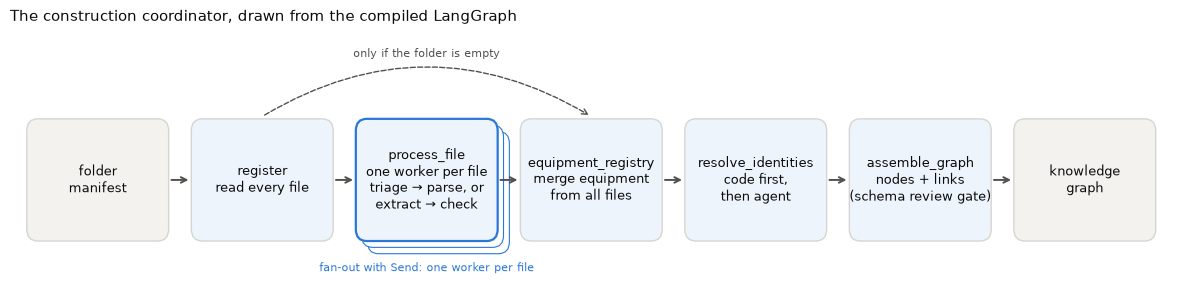

In [11]:
draw_pipeline(kb.graph)

In [12]:
state = kb.graph.invoke({"files": [], "held": []})
bundle = bundle_from(state["builder"], "replay")
print(f"{len(bundle.nodes)} nodes, {len(bundle.edges)} links, {len(bundle.held)} held (no model calls)")
order = [s["id"] for s in manifest["sources"]]
pd.DataFrame([
    {"id": r.source.source_id, "type": r.doc_type, "read by": r.method, "facts": len(r.facts),
     "steps": " → ".join(s["stage"] for s in r.trace)}
    for r in sorted(state["files"], key=lambda r: order.index(r.source.source_id))
])

66 nodes, 53 links, 3 held (no model calls)


,id,type,read by,facts,steps
0,E1,equipment_list,agent: extraction,15,triage → extract
1,E2,event_log,parser: controller log,5,triage
2,E3,handover,agent: extraction,6,triage → extract → reconcile
3,E4,maintenance_history,agent: extraction,3,triage → extract → reconcile
4,E5,manual,agent: extraction,1,triage → extract → correct
5,E6,manual,agent: extraction,1,triage → extract → correct
6,E7a,approved_parts,agent: extraction,2,triage → extract
7,E7b,stock_list,agent: extraction,1,triage → extract
8,E8,policy_summary,agent: extraction,1,triage → extract
9,N1,maintenance_history,agent: extraction,1,triage → extract → correct → extract → reroute


## 7. Equipment registry and identity resolution

Equipment from the walkdown notes (E1, agent) and the asset register (R1, parser) merges into
one node per identifier, with all names and aliases. Conflicting configurations would be held.

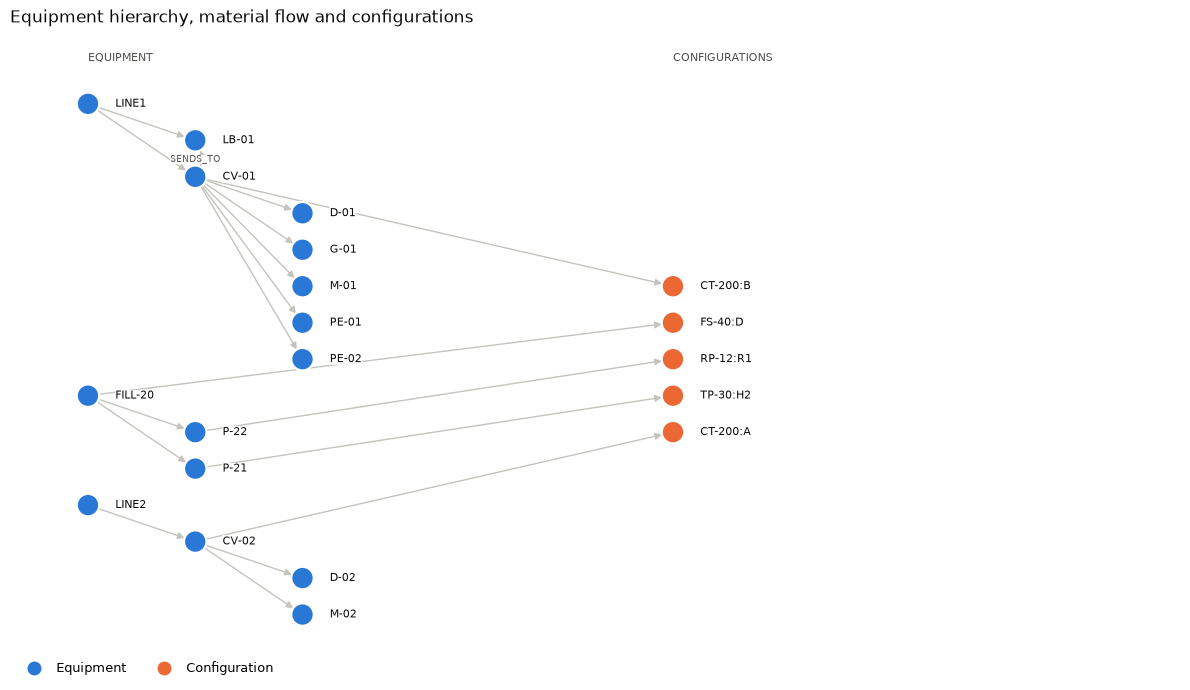

In [13]:
draw_graph(subgraph(bundle, {"HAS_COMPONENT", "SENDS_TO", "HAS_CONFIGURATION"}),
           "Equipment hierarchy, material flow and configurations", edge_labels={"SENDS_TO"}, size=(12, 7))

- The flow "carton packer → CV-01" is held: the carton packer has no identifier.
- CV-01 and CV-02 are the same model in different configurations (B and A).
- Limitation: LINE1 is named "carton packer", because those words follow `Line 1:` in the
  source. Checks prove a value is in the file, not that it was interpreted correctly; gold
  checks and review cover that gap.

Logs, notes and work orders refer to equipment informally. Code resolves exact IDs, names and
aliases (ignoring case, spaces and hyphens); only the remainder goes to the reconciliation
agent, which answers *match*, *ambiguous* or *unresolved*. Agent matches must name a registry
ID and stay labelled as such.

In [14]:
pd.DataFrame([
    {"source": sid, "mention": mention, "resolved to": r["id"] or "— held", "by": r["by"],
     "basis": short(r["basis"], 85)}
    for sid, mentions in state["resolutions"].items() for mention, r in mentions.items()
])

,source,mention,resolved to,by,basis
0,E2,LINE1,LINE1,code,"exact ID, name or alias"
1,E2,D-01,D-01,code,"exact ID, name or alias"
2,E2,CV-01,CV-01,code,"exact ID, name or alias"
3,E2,LB-01,LB-01,code,"exact ID, name or alias"
4,E3,Line 1,LINE1,code,"exact ID, name or alias"
5,E3,Motor,— held,agent,ambiguous: mention 'Motor' matches multiple entries M-01 and M-02
6,E3,outfeed belt,CV-01,code,"exact ID, name or alias"
7,E4,CV01 / line 1,CV-01,agent,CV01 matches CV-01 ID ignoring hyphen
8,E4,CV-02 / line 2 case packer outfeed,CV-02,agent,CV-02 and 'case packer outfeed' alias match
9,E4,packing outfeed CV-01,CV-01,code,mention contains a recorded ID or alias


"outfeed" (N3) could be CV-01 or CV-02 and is held rather than guessed. "Motor" (E3) is also
ambiguous; that statement falls back to the note's scope, LINE1.

## 8. The assembled graph

Link types, and the node kinds each may join, are fixed in code (`EDGE_TYPES`);
`validate_links()` rejects anything else. Repeated facts merge their evidence.

,Equipment,Configuration,Document,ProcedureReference,AlarmType,Part,Event,MaintenanceCase,Finding,StockRecord
nodes,16,5,14,1,1,3,10,7,6,3


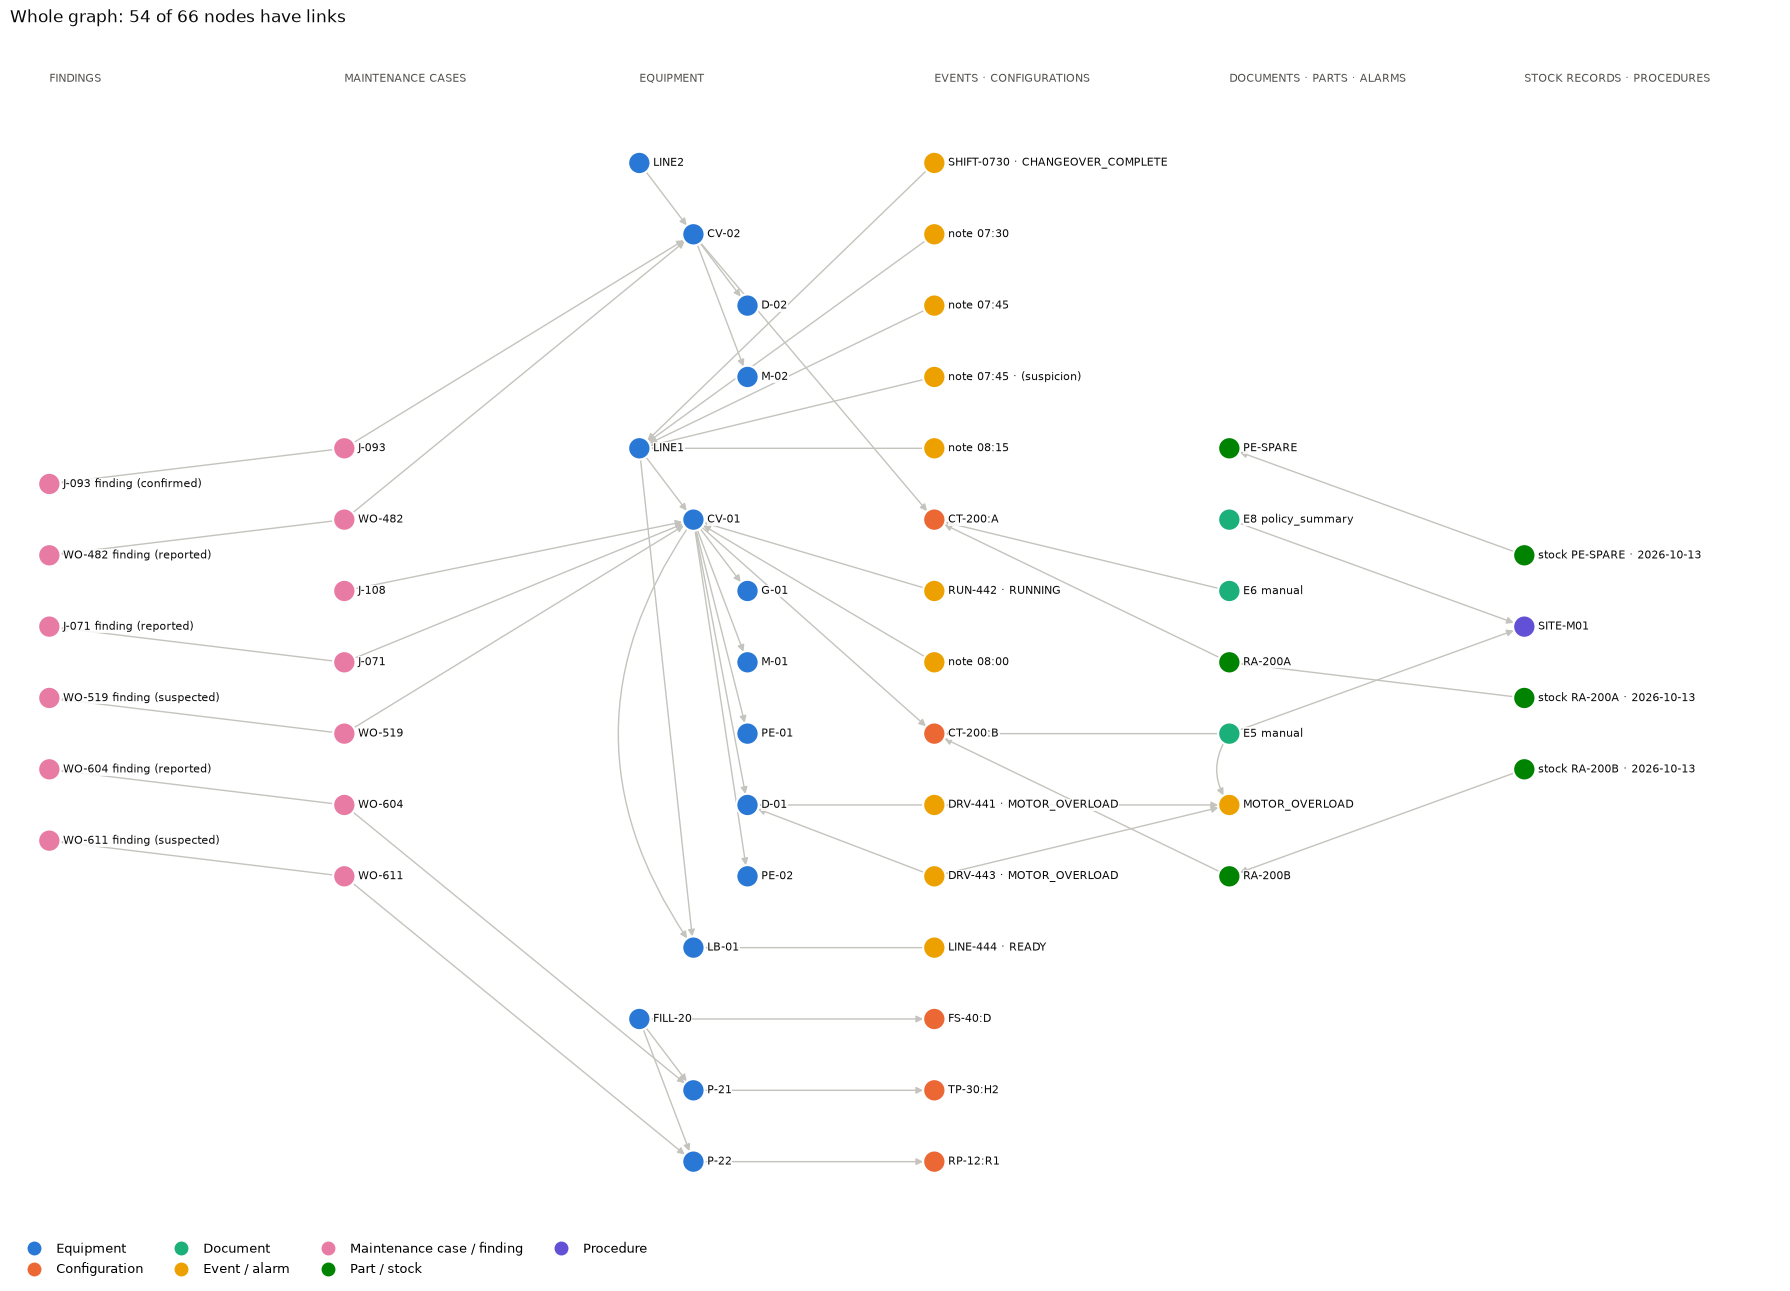

In [15]:
G = to_networkx(bundle)
display(pd.DataFrame({"nodes": Counter(n.kind for n in bundle.nodes)}).T)
linked = G.subgraph([n for n in G if G.degree(n) > 0])
draw_graph(linked, f"Whole graph: {linked.number_of_nodes()} of {G.number_of_nodes()} nodes have links",
           size=(18, 13))

Unlinked nodes are mostly documents: facts refer to them through evidence, not links.
PLC-01 is unlinked because the source only describes a signal, which is not treated as
membership.

Neighbourhood of CV-01:

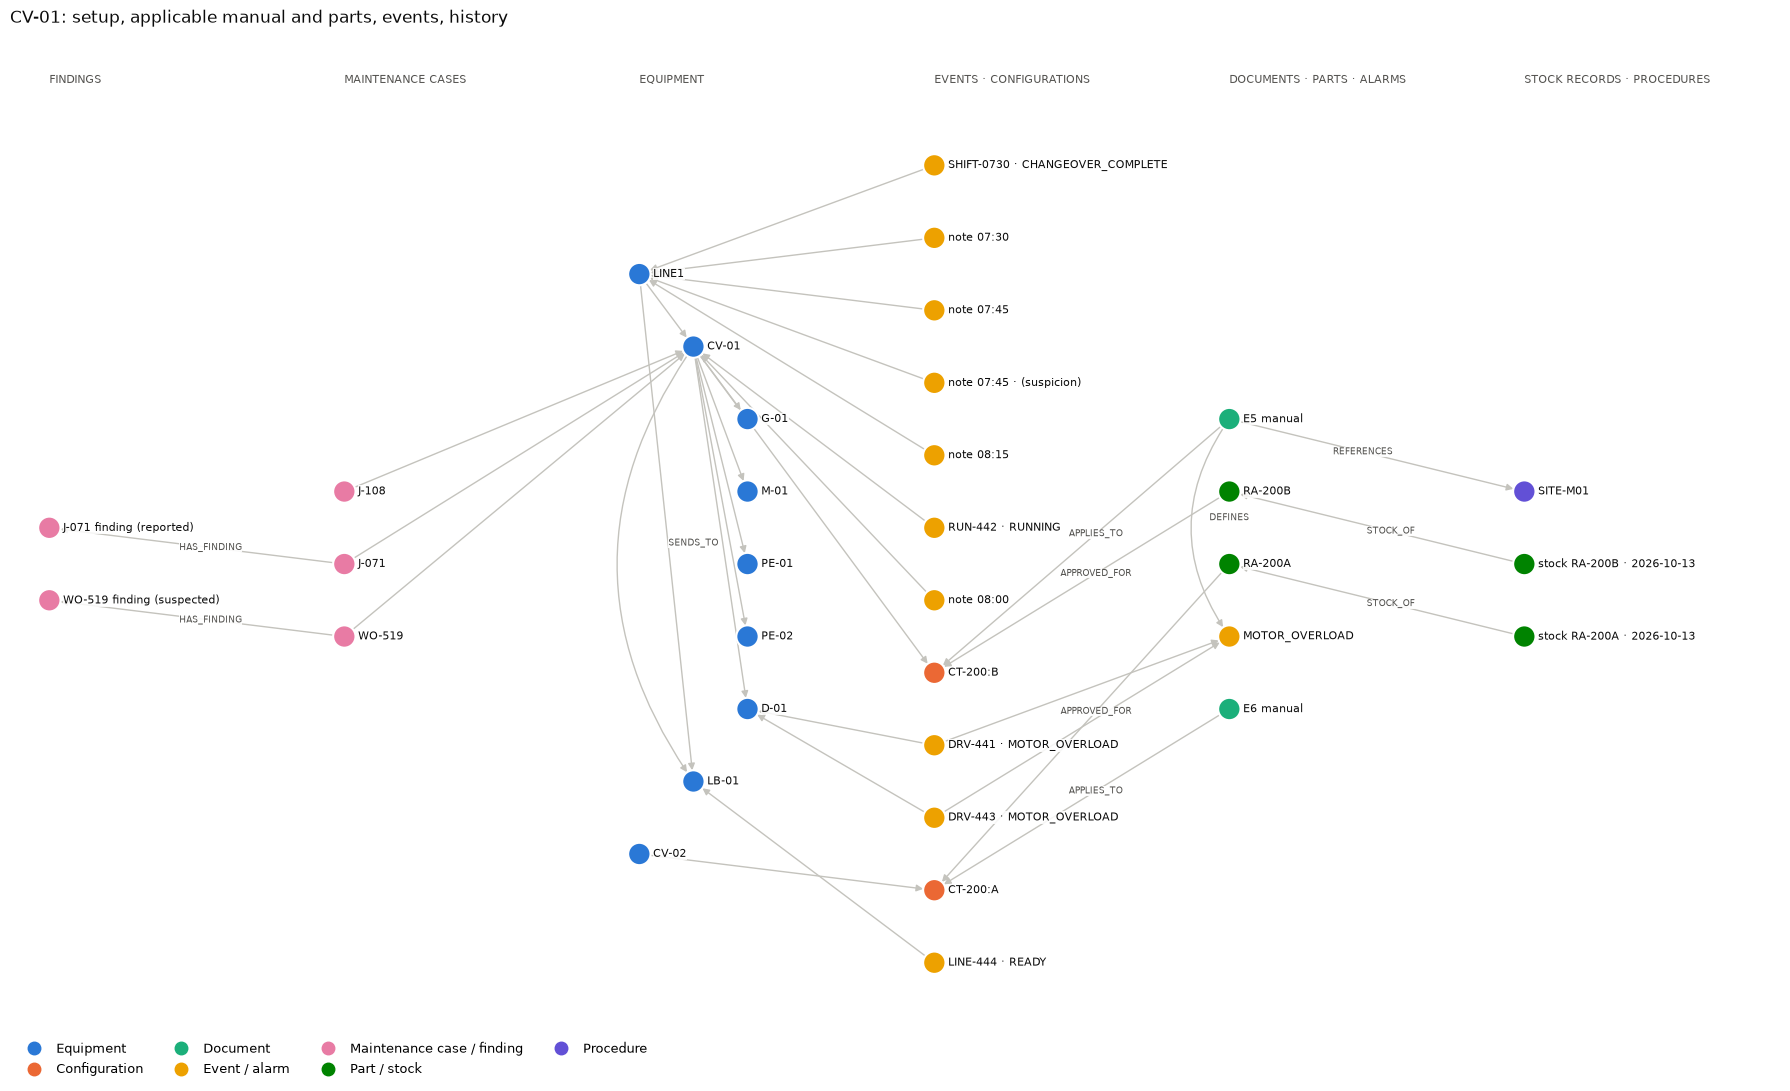

In [16]:
near = neighbourhood(G, "CV-01", hops=2, keep=lambda n: G.nodes[n]["kind"] != "Document" or n == "document:E5")
extra = ["alarm:MOTOR_OVERLOAD", "procedure:SITE-M01", "document:E6", "CT-200:A", "part:RA-200A", "CV-02"]
extra += [e.source for e in bundle.edges if e.relation == "STOCK_OF" and e.target in {"part:RA-200B", "part:RA-200A"}]
draw_graph(G.subgraph(set(near) | set(extra)).copy(), "CV-01: setup, applicable manual and parts, events, history",
           edge_labels={"APPLIES_TO", "APPROVED_FOR", "STOCK_OF", "DEFINES", "REFERENCES", "HAS_FINDING", "SENDS_TO"},
           size=(18, 11))

Manuals and parts apply to a configuration, not to a machine, so applicability is a path
through the graph:

In [17]:
for machine in ["CV-01", "CV-02"]:
    configs = {e.target for e in bundle.edges if e.source == machine and e.relation == "HAS_CONFIGURATION"}
    manuals = sorted(e.source for e in bundle.edges if e.relation == "APPLIES_TO" and e.target in configs)
    parts = sorted(e.source for e in bundle.edges if e.relation == "APPROVED_FOR" and e.target in configs)
    print(f"{machine} → {', '.join(configs)} ← manuals {manuals}, approved parts {parts}")

link = next(e for e in bundle.edges if e.source == "document:E5" and e.relation == "APPLIES_TO")
print(f"\nEvidence for {link.source} —{link.relation}→ {link.target}:")
evidence_frame(link.evidence)

CV-01 → CT-200:B ← manuals ['document:E5'], approved parts ['part:RA-200B']
CV-02 → CT-200:A ← manuals ['document:E6'], approved parts ['part:RA-200A']

Evidence for document:E5 —APPLIES_TO→ CT-200:B:


,source,file,line,page,exact text in the file
0,E5,CT-200_configuration_B_rev3.pdf,4,1,CT-200 conveyor
1,E5,CT-200_configuration_B_rev3.pdf,5,1,Configuration B


## 9. Held items and schema review

In [18]:
pd.DataFrame(bundle.held)

,source,stage,item,reason
0,E1,equipment,CARTONPACKER -> CV-01,Flow names unknown equipment.
1,N3,identity,WO-527,Equipment 'outfeed': ambiguous: mention 'outfeed' matches multiple aliases including 'outfeed belt' (CV-01...
2,C3,schema review,quantity_reserved,"New stock fields await review (proposal 4264280c8ea77122, pending)."


C3 has a `quantity_reserved` column that the stock schema does not define. The mapping agent
proposed a field; the build filed it for review and held only that file's records. Approving
it and replaying the build (still no model calls):

In [19]:
review = SchemaReview(RUNTIME / "review.sqlite")
proposal = review.proposals()[0]
print("Proposed:", proposal["fields"])
review.decide(proposal["id"], ReviewDecision(
    action="approve", reviewer="walkthrough", note="Reserved units cannot be issued.",
    proposal_fingerprint=proposal["fingerprint"], event_id=str(uuid4())))
approved = build_knowledge(ROOT, RUNTIME)
print(f"Schema v{review.schema().version}; stock records {len(stock_table(bundle))} → {len(stock_table(approved))}")
stock_table(approved)

Proposed: [{'name': 'quantity_reserved', 'data_type': 'integer', 'description': 'Quantity of parts reserved and not available for use'}]
Schema v2; stock records 3 → 5


,part,location,counted_at,on hand,reserved,schema
0,PE-SPARE,C-03,2026-10-13T16:00,2,not recorded,2
1,RA-200A,B-11,2026-10-13T16:00,3,not recorded,2
2,RA-200A,"Stores, B-11",2026-10-16T16:00,3,0,2
3,RA-200B,B-12,2026-10-13T16:00,1,not recorded,2
4,RA-200B,"Stores, B-12",2026-10-16T16:00,2,1,2


Approval changes the schema, not the counts. Counts remain dated snapshots, and an
unrecorded reservation stays unrecorded rather than becoming zero.

## 10. Validation

Gold checks are hand-written expected links, forbidden links, properties and evidence
counts. They are never shown to the agents.

In [20]:
gold = {g: gold_check(bundle, ROOT / "evaluation" / g)
        for g in ["construction_gold.json", "document_gold.json", "maintenance_gold.json"]}
display(pd.DataFrame([{"gold file": g, "passed": r["passed"], "total": r["total"]} for g, r in gold.items()]))

nodes = {n.id: n for n in bundle.nodes}
edges = {(e.source, e.relation, e.target) for e in bundle.edges}
events_ = [n for n in bundle.nodes if n.kind == "Event"]
kept = [
    ("DRV-441 exported twice", "one event, two source lines", len(nodes["E2:DRV-441"].evidence) == 2),
    ("overload stops", "exactly two MOTOR_OVERLOAD events",
     sum(n.properties["code"] == "MOTOR_OVERLOAD" for n in events_) == 2),
    ('"Motor getting tired? Just my guess"', "UNVERIFIED_SUSPICION note",
     any(n.properties["code"] == "UNVERIFIED_SUSPICION" and "Motor" in n.properties["message"] for n in events_)),
    ("J-093 motor replacement", "recorded for CV-02, not CV-01",
     ("case:J-093", "RECORDED_FOR", "CV-02") in edges and ("case:J-093", "RECORDED_FOR", "CV-01") not in edges),
    ("J-071, before the upgrade", "configuration at the time: A",
     nodes["case:J-071"].properties["configuration_at_time"] == "A"),
    ("two CT-200 manuals", "E5 → CT-200:B, E6 → CT-200:A",
     {("document:E5", "APPLIES_TO", "CT-200:B"), ("document:E6", "APPLIES_TO", "CT-200:A")} <= edges),
    ('"Possibly dust on the detector lens"', "suspected finding",
     nodes["case:WO-519:finding"].properties["status"] == "suspected"),
    ('untagged "outfeed" callout', "held, not linked", "case:WO-527" not in nodes),
]
pd.DataFrame([{"source": a, "stored as": b, "ok": "✅" if ok else "❌"} for a, b, ok in kept])

,gold file,passed,total
0,construction_gold.json,23,23
1,document_gold.json,12,12
2,maintenance_gold.json,18,18


,source,stored as,ok
0,DRV-441 exported twice,"one event, two source lines",✅
1,overload stops,exactly two MOTOR_OVERLOAD events,✅
2,"""Motor getting tired? Just my guess""",UNVERIFIED_SUSPICION note,✅
3,J-093 motor replacement,"recorded for CV-02, not CV-01",✅
4,"J-071, before the upgrade",configuration at the time: A,✅
5,two CT-200 manuals,"E5 → CT-200:B, E6 → CT-200:A",✅
6,"""Possibly dust on the detector lens""",suspected finding,✅
7,"untagged ""outfeed"" callout","held, not linked",✅


## 11. Replay, live and incremental builds

Each agent decision is cached under a hash of its instructions, output contract and input.
Changing a file invalidates only that file's decisions; in replay mode the file is held
rather than guessed. The same pipeline also builds a different folder with no code change.

In [21]:
edited = src["E3"].model_copy(update={"text": src["E3"].text + "\n08:19 - checked underneath."})
print("Edited E3 in replay:", kb.process(edited).held[0]["reason"])

other = build_knowledge(ROOT, RUNTIME, folder="data/scenarios/sensor_stop")
print(f"Sensor-stop folder: {len(other.nodes)} nodes, {len(other.edges)} links, {len(other.held)} held")
pd.DataFrame([{k: t[k] for k in ("source_id", "doc_type", "method", "facts")} for t in other.extraction_trace])

Edited E3 in replay: No recorded triage decision for this version of the file; run a live build.
Sensor-stop folder: 17 nodes, 16 links, 0 held


,source_id,doc_type,method,facts
0,S1,equipment_list,parser: equipment register,3
1,S2,event_log,parser: controller log,3
2,S3,manual,agent: extraction,1
3,S4,handover,agent: extraction,4
4,S5,policy_summary,agent: extraction,1


Live build (sends only new or changed inputs to the model; needs `OPENAI_API_KEY` in `.env`):

```bash
.venv/bin/factory-demo build --mode live
```

## Summary

| Stage | Guards against |
|---|---|
| Read: hash, line and page map | untraceable citations |
| Triage by content, with a second choice | routing by file name or format |
| Deterministic parsers | duplicate events counted twice |
| Quotes and labels, verified by code | invented or paraphrased evidence |
| One correction, one re-route | silent failures; per-file special cases |
| Identity: code first, ambiguous mentions held | linking history to the wrong machine |
| Link types fixed in code | model-invented relationships |
| Human schema review; dated counts | silent schema changes; stale stock read as current |

Next: retrieval. The assistant queries this graph with read-only tools, using the
08:20 cut-off.

Continue with [02_question_to_answer_concise.ipynb](02_question_to_answer_concise.ipynb): how the assistant answers from this graph.